In [1]:
!pip install gensim scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 31.3 MB/s eta 0:00:00


In [5]:
from gensim.models import Word2Vec
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

In [3]:
sentences = [
    ["king", "queen", "prince", "princess", "royal"],
    ["man", "woman", "boy", "girl"],
    ["dog", "puppy", "cat", "kitten", "animal"],
    ["lion", "tiger", "animal"],
    ["apple", "banana", "orange", "fruit"],
    ["mango", "grape", "fruit"],
    ["car", "truck", "bus", "vehicle"],
    ["bike", "motorcycle", "vehicle"],
    ["python", "java", "programming", "coding"],
    ["sql", "database", "query", "data"],
    ["machine", "learning", "deep", "learning", "ai"],
    ["artificial", "intelligence", "ai", "machine"],
    ["doctor", "hospital", "medicine", "health"],
    ["teacher", "student", "school", "education"]
]

In [6]:
model = Word2Vec(
    sentences,
    vector_size=50,
    window=3,
    min_count=1,
    workers=4,
    epochs=500
)

In [8]:
words = list(model.wv.index_to_key)
vectors = np.array([model.wv[word] for word in words])

In [9]:
tsne = TSNE(
    n_components=2,
    perplexity=5,
    random_state=42
)

In [11]:
embeddings_2d = tsne.fit_transform(vectors)

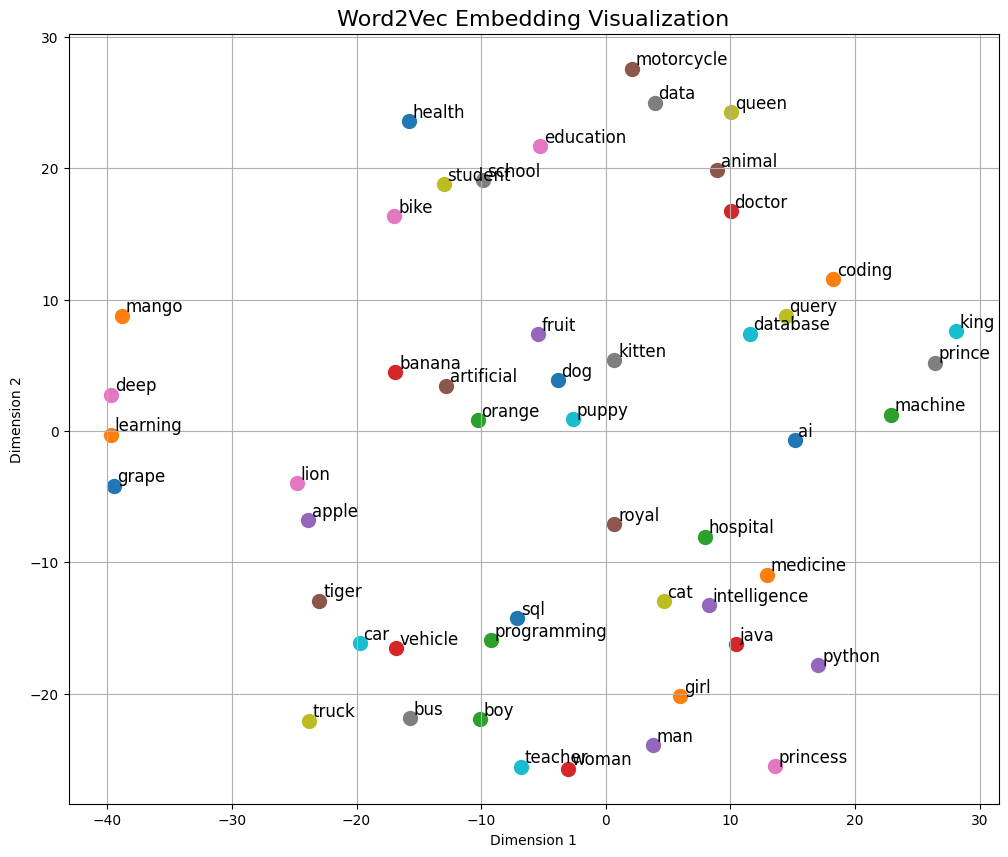

In [12]:
plt.figure(figsize=(12, 10))

for i, word in enumerate(words):
    x = embeddings_2d[i, 0]
    y = embeddings_2d[i, 1]

    plt.scatter(x, y, s=100)
    plt.text(x + 0.3, y + 0.3, word, fontsize=12)

plt.title("Word2Vec Embedding Visualization", fontsize=16)
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.grid(True)
plt.show()

In [13]:
model.wv.most_similar("king")

[('prince', 0.6064209342002869),
 ('java', 0.5751421451568604),
 ('queen', 0.5659464597702026),
 ('machine', 0.5405269265174866),
 ('student', 0.5370253920555115),
 ('dog', 0.5288169384002686),
 ('education', 0.5233431458473206),
 ('kitten', 0.5163149833679199),
 ('royal', 0.5084719061851501),
 ('coding', 0.4911346435546875)]

In [14]:
model.wv.similarity("king", "queen")

np.float32(0.56594646)